In [16]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ==========================================
# CONFIGURACIÓN
# ==========================================
ANIO = 2025
GRAN_PREMIO = "Spain"
BASE = "https://api.openf1.org/v1"

In [17]:
# ==========================================
# 1. FUNCIÓN PARA CONSULTAR OPENF1
# ==========================================
def consultar(endpoint, params=None):
    respuesta = requests.get(
        f"{BASE}/{endpoint}",
        params=params,
        timeout=60
    )
    respuesta.raise_for_status()
    return respuesta.json()

In [18]:
# ==========================================
# 2. BUSCAR LA CARRERA
# ==========================================
sesiones = pd.DataFrame(
    consultar(
        "sessions",
        {
            "year": ANIO,
            "session_name": "Race",
            "country_name": GRAN_PREMIO
        }
    )
)

if sesiones.empty:
    raise ValueError(
        "No se encontró la carrera. "
        "Comprueba el año y el nombre del Gran Premio."
    )

sesion = sesiones.sort_values("date_start").iloc[0]
session_key = int(sesion["session_key"])

print("Carrera:", sesion["country_name"], "GP")
print("Circuito:", sesion["circuit_short_name"])
print("Fecha:", sesion["date_start"])
print("Session key:", session_key)

Carrera: Spain GP
Circuito: Catalunya
Fecha: 2025-06-01T13:00:00+00:00
Session key: 9971


In [19]:
# ==========================================
# 3. DESCARGAR LOS TIEMPOS POR VUELTA
# ==========================================
vueltas = pd.DataFrame(
    consultar(
        "laps",
        {"session_key": session_key}
    )
)

if vueltas.empty:
    raise ValueError(
        "No se encontraron tiempos por vuelta."
    )

# Asegurar que los tiempos y números de vuelta sean numéricos
vueltas["lap_duration"] = pd.to_numeric(
    vueltas["lap_duration"],
    errors="coerce"
)

vueltas["lap_number"] = pd.to_numeric(
    vueltas["lap_number"],
    errors="coerce"
)

# Eliminar vueltas sin tiempo registrado
vueltas = vueltas.dropna(
    subset=["lap_duration", "driver_number", "lap_number"]
)

# Excluir vueltas de entrada a boxes, si la API las identifica
if "is_pit_out_lap" in vueltas.columns:
    vueltas = vueltas[
        vueltas["is_pit_out_lap"] != True
    ].copy()

# Eliminar tiempos imposibles o claramente inválidos
vueltas = vueltas[
    (vueltas["lap_duration"] > 0) &
    (vueltas["lap_duration"] < 200)
].copy()

In [20]:
# ==========================================
# 4. OBTENER LOS NOMBRES DE LOS PILOTOS
# ==========================================
pilotos = pd.DataFrame(
    consultar(
        "drivers",
        {"session_key": session_key}
    )
)

if pilotos.empty:
    raise ValueError(
        "No se encontraron nombres de pilotos."
    )

nombres = pilotos[
    ["driver_number", "full_name"]
].drop_duplicates("driver_number")

# Unificar el tipo de dato para poder combinar las tablas
vueltas["driver_number"] = (
    vueltas["driver_number"].astype(str)
)
nombres["driver_number"] = (
    nombres["driver_number"].astype(str)
)

vueltas = vueltas.merge(
    nombres,
    on="driver_number",
    how="left"
)

vueltas["piloto"] = vueltas["full_name"].fillna(
    "Piloto " + vueltas["driver_number"]
)

In [21]:
# ==========================================
# 5. FILTRAR TIEMPOS ANÓMALOS
# ==========================================
# Para reducir el efecto de vueltas extremadamente lentas
# (por ejemplo, incidentes o entradas a boxes no identificadas),
# conservar tiempos razonablemente cercanos a la mediana de cada piloto.

def filtrar_vueltas(grupo):
    mediana = grupo["lap_duration"].median()

    return grupo[
        grupo["lap_duration"].between(
            mediana * 0.90,
            mediana * 1.10
        )
    ]

vueltas = (
    vueltas.groupby("piloto", group_keys=False)
    .apply(filtrar_vueltas)
    .reset_index(drop=True)
)

if vueltas.empty:
    raise ValueError(
        "No quedan tiempos válidos para representar."
    )

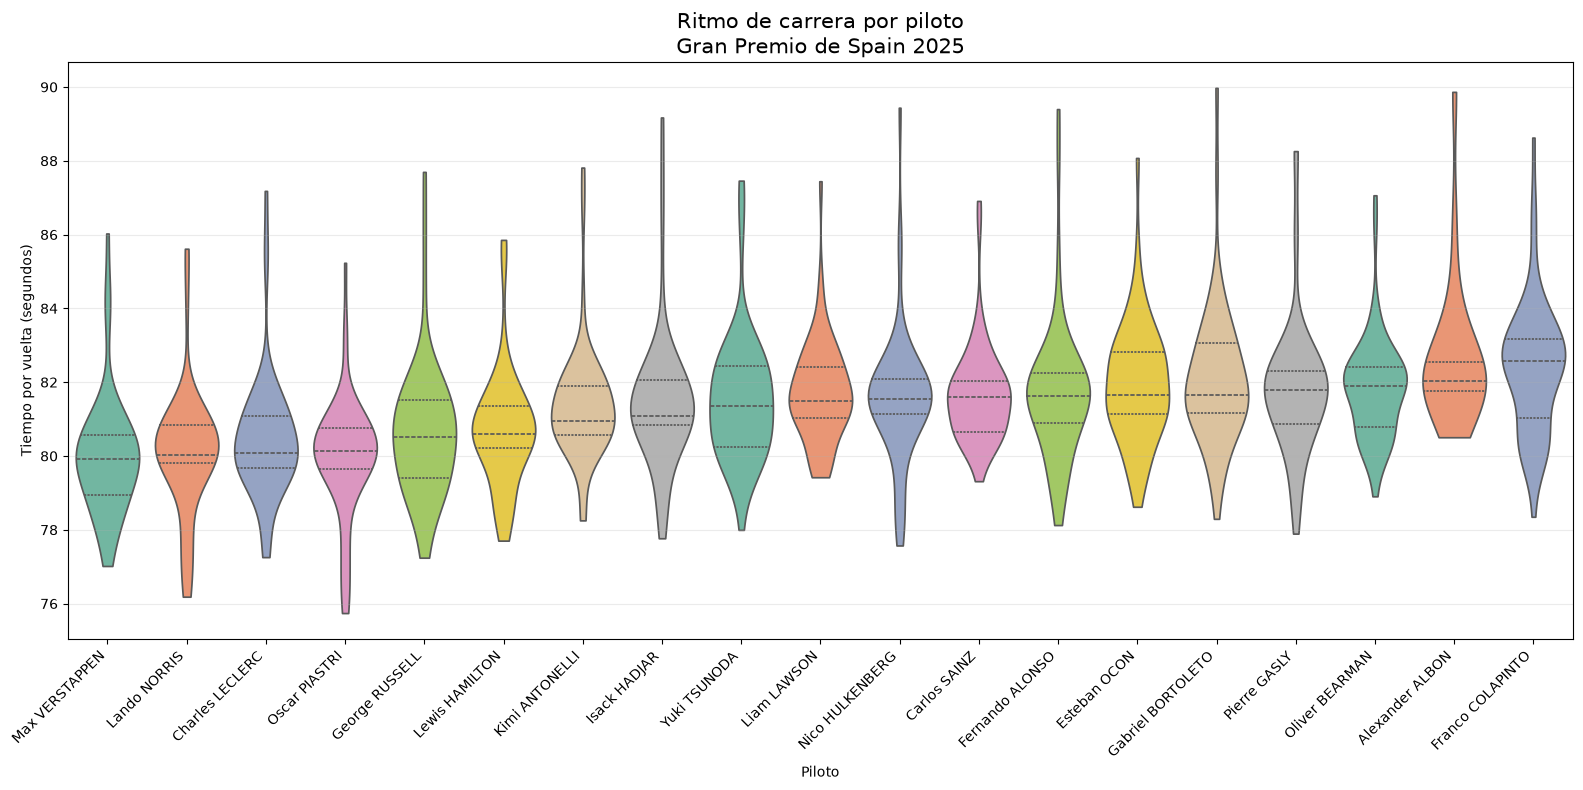

In [24]:
# ==========================================
# 6. CREAR EL VIOLIN PLOT
# ==========================================
# Ordenar los pilotos por su mediana de tiempo por vuelta
orden_pilotos = (
    vueltas.groupby("full_name")["lap_duration"]
    .median()
    .sort_values()
    .index
)

fig, ax = plt.subplots(figsize=(16, 8))

sns.violinplot(
    data=vueltas,
    x="full_name",
    y="lap_duration",
    hue="full_name",
    order=orden_pilotos,
    hue_order=orden_pilotos,
    palette="Set2",
    inner="quartile",
    cut=0,
    legend=False,
    ax=ax
)

ax.set_title(
    f"Ritmo de carrera por piloto\n"
    f"Gran Premio de {GRAN_PREMIO} {ANIO}",
    fontsize=15
)

ax.set_xlabel("Piloto")
ax.set_ylabel("Tiempo por vuelta (segundos)")

ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right")

ax.grid(axis="y", alpha=0.25)

fig.tight_layout()


In [25]:
# ==========================================
# 7. GUARDAR EL GRÁFICO
# ==========================================
ruta = (
    Path.cwd()
    / f"violin_plot_ritmo_{GRAN_PREMIO}_{ANIO}.png"
)

plt.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>